# Machine Learning Project
## Part B: Image Classification

**Dataset:** Flowers Recognition

**Dataset Source:** Kaggle

**Classes:** Daisy, Dandelion, Rose, Sunflower, Tulip

**Models:**
- Logistic Regression
- K-Nearest Neighbors (KNN) Classifier
- K-Means Clustering

In [ ]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt

from google.colab import drive
from pathlib import Path
from PIL import Image
from collections import Counter
from skimage.feature import hog
from sklearn.model_selection import train_test_split

In [ ]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
dataset_path = '/content/drive/MyDrive/DataSets/Image dataset/flowers'
processed_path = '/content/drive/MyDrive/DataSets/Image dataset/Processed'
os.makedirs(processed_path, exist_ok=True)
classes = ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']
image_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
print("Dataset exists:", os.path.exists(dataset_path))
print("Processed folder exists:", os.path.exists(processed_path))

Dataset exists: True
Processed folder exists: True


In [ ]:
image_files = [
    file for file in Path(dataset_path).rglob('*')
    if file.suffix.lower() in image_extensions
]

print("Total images:", len(image_files))

Total images: 4317


In [ ]:
total_images = 0

for class_name in classes:
    class_path = os.path.join(dataset_path, class_name)

    images = []

    for root, dirs, files in os.walk(class_path):
        for file in files:
            if file.lower().endswith(image_extensions):
                images.append(file)

    print(f'{class_name}: {len(images)} images')
    total_images += len(images)

print('-' * 50)
print(f'Total images: {total_images}')

daisy: 764 images
dandelion: 1052 images
rose: 784 images
sunflower: 733 images
tulip: 984 images
--------------------------------------------------
Total images: 4317


In [ ]:
corrupted_images = []
valid_images = []

for class_name in classes:
    class_path = os.path.join(dataset_path, class_name)

    for root, dirs, files in os.walk(class_path):
        for file in files:
            if file.lower().endswith(image_extensions):
                image_path = os.path.join(root, file)

                try:
                    with Image.open(image_path) as img:
                        img.verify()

                    valid_images.append(image_path)

                except Exception:
                    corrupted_images.append(image_path)

print("Valid images:", len(valid_images))
print("Corrupted images:", len(corrupted_images))

print("\nCorrupted files:")
for image_path in corrupted_images:
    print(image_path)

Valid images: 4317
Corrupted images: 0

Corrupted files:


In [ ]:
image_size = (64, 64)

X_images = []
y_labels = []

for image_path in valid_images:
    class_name = os.path.basename(os.path.dirname(image_path))

    image = Image.open(image_path).convert('RGB')
    image = image.resize(image_size)

    image_array = np.array(image)
    image_array = image_array / 255.0

    X_images.append(image_array)
    y_labels.append(class_name)

X_images = np.array(X_images, dtype=np.float32)
y_labels = np.array(y_labels)

print("Images shape:", X_images.shape)
print("Labels shape:", y_labels.shape)
print("Minimum pixel value:", X_images.min())
print("Maximum pixel value:", X_images.max())

Images shape: (4317, 64, 64, 3)
Labels shape: (4317,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [ ]:
X_raw = X_images.reshape(len(X_images), -1)

print("Raw Pixels shape:", X_raw.shape)


Raw Pixels shape: (4317, 12288)


In [ ]:
X_hog = []

for image in X_images:
    gray_image = np.mean(image, axis=2)

    hog_features = hog(
        gray_image,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm='L2-Hys'
    )

    X_hog.append(hog_features)

X_hog = np.array(X_hog)

print("HOG shape:", X_hog.shape)

HOG shape: (4317, 1764)


In [ ]:
X_color = []

for image in X_images:
    hist_features = []

    for channel in range(3):
        hist, _ = np.histogram(
            image[:, :, channel],
            bins=32,
            range=(0, 1)
        )

        hist = hist / hist.sum()
        hist_features.extend(hist)

    X_color.append(hist_features)

X_color = np.array(X_color)

print("Color Histogram shape:", X_color.shape)

Color Histogram shape: (4317, 96)


In [ ]:
indices = np.arange(len(y_labels))

train_indices, temp_indices = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    stratify=y_labels
)

val_indices, test_indices = train_test_split(
    temp_indices,
    test_size=0.50,
    random_state=42,
    stratify=y_labels[temp_indices]
)

print("Train samples:", len(train_indices))
print("Validation samples:", len(val_indices))
print("Test samples:", len(test_indices))

Train samples: 3021
Validation samples: 648
Test samples: 648


In [ ]:
X_raw_train = X_raw[train_indices]
X_raw_val = X_raw[val_indices]
X_raw_test = X_raw[test_indices]

X_hog_train = X_hog[train_indices]
X_hog_val = X_hog[val_indices]
X_hog_test = X_hog[test_indices]

X_color_train = X_color[train_indices]
X_color_val = X_color[val_indices]
X_color_test = X_color[test_indices]

y_train = y_labels[train_indices]
y_val = y_labels[val_indices]
y_test = y_labels[test_indices]

print("Raw Pixels:")
print(X_raw_train.shape, X_raw_val.shape, X_raw_test.shape)

print("\nHOG:")
print(X_hog_train.shape, X_hog_val.shape, X_hog_test.shape)

print("\nColor Histogram:")
print(X_color_train.shape, X_color_val.shape, X_color_test.shape)

print("\nLabels:")
print(y_train.shape, y_val.shape, y_test.shape)

Raw Pixels:
(3021, 12288) (648, 12288) (648, 12288)

HOG:
(3021, 1764) (648, 1764) (648, 1764)

Color Histogram:
(3021, 96) (648, 96) (648, 96)

Labels:
(3021,) (648,) (648,)


In [ ]:
print("Training distribution:")
print(Counter(y_train))

print("\nValidation distribution:")
print(Counter(y_val))

print("\nTesting distribution:")
print(Counter(y_test))

Training distribution:
Counter({np.str_('dandelion'): 736, np.str_('tulip'): 688, np.str_('rose'): 549, np.str_('daisy'): 535, np.str_('sunflower'): 513})

Validation distribution:
Counter({np.str_('dandelion'): 158, np.str_('tulip'): 148, np.str_('rose'): 118, np.str_('daisy'): 114, np.str_('sunflower'): 110})

Testing distribution:
Counter({np.str_('dandelion'): 158, np.str_('tulip'): 148, np.str_('rose'): 117, np.str_('daisy'): 115, np.str_('sunflower'): 110})


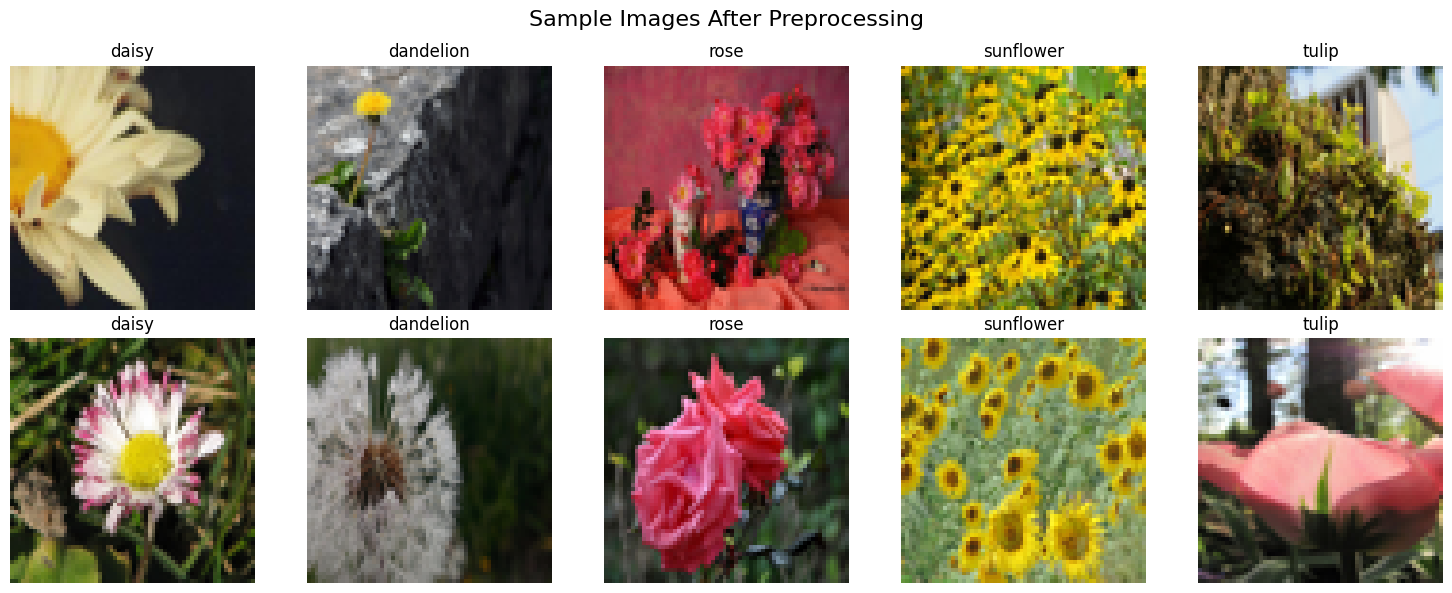

In [ ]:
classes = ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']

plt.figure(figsize=(15, 6))

for i, class_name in enumerate(classes):
    class_indices = np.where(y_labels == class_name)[0]
    selected_indices = random.Random(100).sample(list(class_indices), 2)

    for j, idx in enumerate(selected_indices):
        plt.subplot(2, 5, j * 5 + i + 1)

        plt.imshow(X_images[idx])
        plt.title(class_name)
        plt.axis('off')

plt.suptitle("Sample Images After Preprocessing", fontsize=16)
plt.tight_layout()
plt.show()

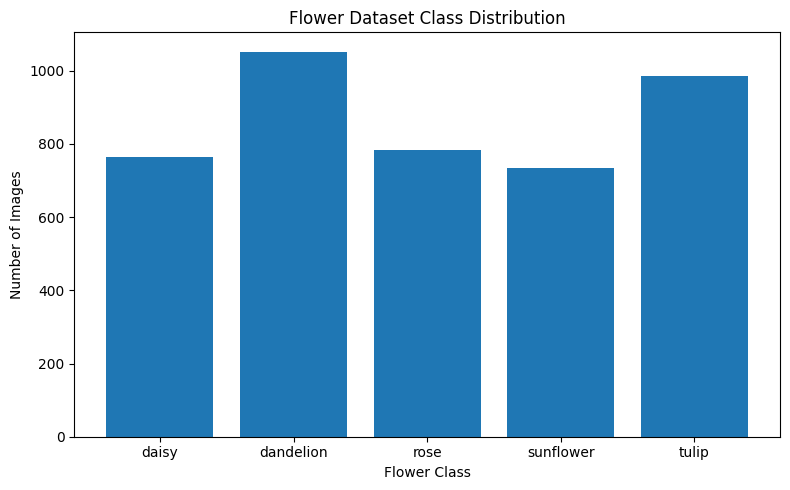

In [ ]:
class_counts = Counter(y_labels)

plt.figure(figsize=(8, 5))

plt.bar(class_counts.keys(), class_counts.values())

plt.title("Flower Dataset Class Distribution")
plt.xlabel("Flower Class")
plt.ylabel("Number of Images")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:
np.savez_compressed(
    os.path.join(processed_path, 'train_data.npz'),
    X_raw=X_raw_train,
    X_hog=X_hog_train,
    X_color=X_color_train,
    y=y_train
)

np.savez_compressed(
    os.path.join(processed_path, 'validation_data.npz'),
    X_raw=X_raw_val,
    X_hog=X_hog_val,
    X_color=X_color_val,
    y=y_val
)

np.savez_compressed(
    os.path.join(processed_path, 'test_data.npz'),
    X_raw=X_raw_test,
    X_hog=X_hog_test,
    X_color=X_color_test,
    y=y_test
)

print("Data saved successfully!")

print("Saved files:")
print(os.listdir(processed_path))

Data saved successfully!
Saved files:
['train_data.npz', 'validation_data.npz', 'test_data.npz']
